# Step 3: Predict next-year high-cost members
Use 2008 data to predict who lands in the **top 5% of total cost in 2009**. (2010 is skipped because its claims are incomplete.)

In [1]:
import duckdb
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

BASE = Path.home() / "Desktop/projects/claims_analysis"
con = duckdb.connect(str(BASE / "data/claims.duckdb"))

## 1. Build the modeling table
One row per member who appears in both 2008 and 2009. Features come from 2008; the outcome is 2009 total cost.

In [2]:
conditions = {"SP_ALZHDMTA": "alzheimers", "SP_CHF": "heart_failure", "SP_CHRNKIDN": "kidney_disease",
              "SP_CNCR": "cancer", "SP_COPD": "copd", "SP_DEPRESSN": "depression", "SP_DIABETES": "diabetes",
              "SP_ISCHMCHT": "ischemic_heart", "SP_OSTEOPRS": "osteoporosis", "SP_RA_OA": "arthritis",
              "SP_STRKETIA": "stroke"}
flags = ",\n    ".join(f"(m.{col} = 1)::INT AS {name}" for col, name in conditions.items())

con.execute(f"""
CREATE OR REPLACE TABLE model_data AS
WITH s08 AS (
    SELECT DESYNPUF_ID, COUNT(*) AS stays_2008
    FROM stays WHERE year(admit_dt) = 2008 GROUP BY 1
)
SELECT my.DESYNPUF_ID,
    my.age,
    (my.sex = 'Female')::INT AS female,
    my.member_months,
    (CAST(m.BENE_ESRD_IND AS VARCHAR) = 'Y')::INT AS esrd,
    {flags},
    my.ip_paid, my.op_paid, my.prof_paid, my.rx_paid,
    my.total_paid AS cost_2008,
    COALESCE(s08.stays_2008, 0) AS stays_2008,
    nxt.total_paid AS cost_2009
FROM member_year my
JOIN members m      ON m.DESYNPUF_ID = my.DESYNPUF_ID AND m.year = 2008
JOIN member_year nxt ON nxt.DESYNPUF_ID = my.DESYNPUF_ID AND nxt.year = 2009
LEFT JOIN s08       ON s08.DESYNPUF_ID = my.DESYNPUF_ID
WHERE my.year = 2008
""")

df = con.sql("SELECT * FROM model_data").df()
df.shape

(114618, 23)

## 2. Define the outcome and split the data
High-cost = top 5% of 2009 cost. Dollar columns are log-transformed because costs are very skewed (helps logistic regression; trees don't care).

In [7]:
cut = df["cost_2009"].quantile(0.95)
df["high_cost"] = (df["cost_2009"] >= cut).astype(int)
print(f"High-cost threshold: ${cut:,.0f}   High-cost rate: {df.high_cost.mean():.1%}")

money = ["ip_paid", "op_paid", "prof_paid", "rx_paid", "cost_2008"]
X = df.drop(columns=["DESYNPUF_ID", "cost_2009", "high_cost"]).copy()
X[money] = np.log1p(X[money].clip(lower=0))
y = df["high_cost"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)
len(X_train), len(X_test)

High-cost threshold: $20,700   High-cost rate: 5.0%


(80232, 34386)

## 3. Evaluation helper
- **AUC**: how well the model ranks high-cost above others (0.5 = random, 1 = perfect)
- **PR-AUC**: better for rare outcomes; compare to the 5% base rate
- **Precision in top 5%**: of the members we'd flag, how many really end up high-cost
- **Recall in top 5%**: of all real high-cost members, how many we catch

In [8]:
def evaluate(name, score):
    score = np.asarray(score)
    flagged = score >= np.quantile(score, 0.95)
    actual = y_test.values
    return {"model": name,
            "auc": round(roc_auc_score(actual, score), 3),
            "pr_auc": round(average_precision_score(actual, score), 3),
            "precision_top5": round(actual[flagged].mean(), 3),
            "recall_top5": round(actual[flagged].sum() / actual.sum(), 3)}

## 4. Baseline: rank by last year's cost
The standard benchmark in healthcare. A model is only useful if it beats this.

In [9]:
results = [evaluate("Baseline: 2008 cost", X_test["cost_2008"])]
pd.DataFrame(results)

,model,auc,pr_auc,precision_top5,recall_top5
0,Baseline: 2008 cost,0.798,0.185,0.255,0.255


## 5. Logistic regression

In [10]:
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
logit.fit(X_train, y_train)
results.append(evaluate("Logistic regression", logit.predict_proba(X_test)[:, 1]))
pd.DataFrame(results)

,model,auc,pr_auc,precision_top5,recall_top5
0,Baseline: 2008 cost,0.798,0.185,0.255,0.255
1,Logistic regression,0.827,0.299,0.308,0.308


## 6. Gradient boosting

In [11]:
gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42)
gbm.fit(X_train, y_train)
results.append(evaluate("Gradient boosting", gbm.predict_proba(X_test)[:, 1]))
pd.DataFrame(results)

,model,auc,pr_auc,precision_top5,recall_top5
0,Baseline: 2008 cost,0.798,0.185,0.255,0.255
1,Logistic regression,0.827,0.299,0.308,0.308
2,Gradient boosting,0.828,0.311,0.305,0.305


## 7. What drives risk?
Logistic regression coefficients on standardized features: bigger = stronger push toward high cost.

Matplotlib is building the font cache; this may take a moment.


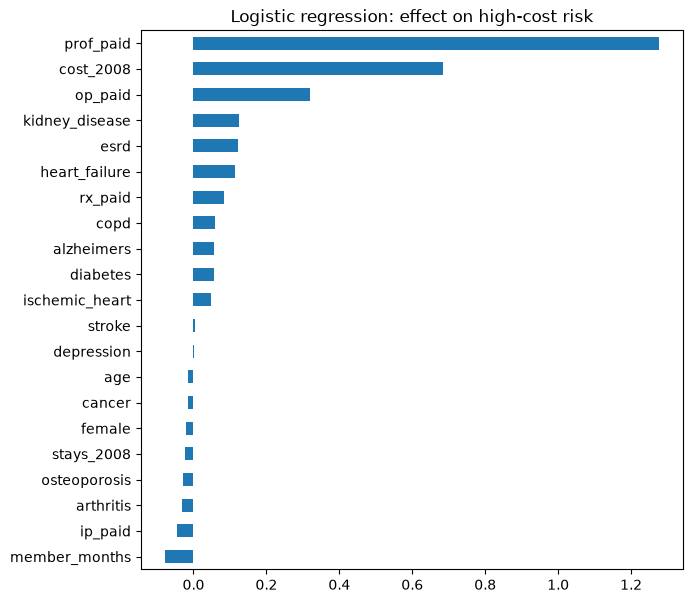

In [12]:
coefs = pd.Series(logit[-1].coef_[0], index=X.columns).sort_values()
coefs.plot.barh(figsize=(7, 7), title="Logistic regression: effect on high-cost risk");

In [15]:
coefs

member_months    -0.077045
ip_paid          -0.044860
arthritis        -0.030523
osteoporosis     -0.029151
stays_2008       -0.022545
female           -0.021799
cancer           -0.015555
age              -0.013880
depression        0.000891
stroke            0.004977
ischemic_heart    0.048997
diabetes          0.055831
alzheimers        0.056815
copd              0.059428
rx_paid           0.082621
heart_failure     0.114839
esrd              0.122730
kidney_disease    0.124722
op_paid           0.318763
cost_2008         0.684011
prof_paid         1.275286
dtype: float64

## 8. Lift by risk decile
Sort members by predicted risk into 10 groups (decile 10 = highest risk). A good model puts most high-cost members in the top decile.

In [13]:
test = X_test.assign(score=gbm.predict_proba(X_test)[:, 1], high_cost=y_test.values,
                     cost_2009=df.loc[X_test.index, "cost_2009"].values)
test["decile"] = pd.qcut(test["score"].rank(method="first"), 10, labels=range(1, 11))

lift = (test.groupby("decile", observed=True)
            .agg(members=("score", "size"),
                 high_cost_rate=("high_cost", "mean"),
                 avg_cost_2009=("cost_2009", "mean"))
            .sort_index(ascending=False))
lift["share_of_high_cost"] = test.groupby("decile", observed=True)["high_cost"].sum() / test["high_cost"].sum()
lift.round(3)

,members,high_cost_rate,avg_cost_2009,share_of_high_cost
decile,,,,
10,3439,0.225,16122.210,0.450
9,3438,0.089,9718.362,0.178
8,3439,0.066,7714.586,0.133
7,3438,0.041,6104.017,0.081
6,3439,0.032,4955.086,0.065
5,3438,0.023,3880.628,0.046
4,3439,0.016,3201.239,0.032
3,3438,0.006,1982.467,0.011
2,3439,0.001,838.351,0.001


## 9. Score every member and save for Power BI
`cross_val_predict` gives each member a score from a model that never saw them (5 folds), so the dashboard isn't showing in-sample results.

In [14]:
df["risk_score"] = cross_val_predict(gbm, X, y, cv=5, method="predict_proba")[:, 1]
rank = df["risk_score"].rank(pct=True)
df["risk_tier"] = np.select([rank > 0.95, rank > 0.80], ["High", "Rising"], default="Low")

risk_scores = df[["DESYNPUF_ID", "age", "female", "cost_2008", "cost_2009",
                  "high_cost", "risk_score", "risk_tier"]]
con.execute("CREATE OR REPLACE TABLE risk_scores AS SELECT * FROM risk_scores")

con.sql("""
SELECT risk_tier, COUNT(*) AS members,
    ROUND(AVG(risk_score), 3) AS avg_score,
    ROUND(100.0 * AVG(high_cost), 1) AS pct_actually_high_cost,
    ROUND(AVG(cost_2009), 0) AS avg_cost_2009
FROM risk_scores GROUP BY risk_tier ORDER BY avg_score DESC
""").df()

,risk_tier,members,avg_score,pct_actually_high_cost,avg_cost_2009
0,High,5731,0.329,32.1,20128.0
1,Rising,17193,0.107,10.7,10670.0
2,Low,91694,0.022,2.2,3648.0
